In [1]:
import pathlib 
import numpy as np
import scipy as sp
from matplotlib import pyplot as plt

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

%load_ext autoreload
%autoreload 2

%matplotlib inline

In [57]:
session_info = {'date': "19_12_2025",
                'genotype_dir': 'R20A02_R56H10_split_CsChrimsontdT_synaptopHluorinVAMP2/pilots',
                'fly': 'fly1',
                'session': 'baseline_opto_response-002',
                'full_genotype': '+; R20A02LexA/UAS-iGABASnFR2; R27F02-Gal4/LexOpCsChrimson::tdT',
                'ecl date': 'ecl: 5/1-4',
                'fictrac_scan_num': 0,
                'fictrac_dat_file' : '',
                'notes':''}


bruker_folder = pathlib.PurePath('/media/mplitt/SSD_storage/2PData')
# pkl_path = pathlib.PurePath(f"/media/mplitt/SSD_storage/fictrac_folder/{session_info['genotype_dir']}/{session_info['date']}/{session_info['fly']}/fly3_1_scan1.pkl")

pp = st2p.preprocessing.EBImagingSession(session_info = session_info, 
                                         bruker_base_dir = bruker_folder,
                                        )


In [58]:
if True:
    gd = session_info['genotype_dir']
    d = session_info['date']
    f = session_info['fly']
    s = session_info['session']
    outdir = pathlib.PurePath(f'/media/mplitt/SSD_storage/2P_scratch/{gd}/{d}/{f}/{s}/preprocess.pkl')
    pp = st2p.preprocessing.EBImagingSession.from_file(outdir)
    # y_r4d = pp.timeseries['rois_R4d_z']
    # y = pp.timeseries['rois_z']
    # n_rois=y.shape[1]

In [18]:
pp.extract_metadata()


In [19]:
pp.bruker_to_h5(first_chan=1, overwrite=False)
data_corr, shifts, error, diffphase= pp.motion_correct(pp.data)

(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)


In [20]:
nap = pp.open_napari()

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/SessionTools/two_photon/preprocessing_tools/napari_tools.py:74: FutureWarning: `napari.view_image` is deprecated and will be removed in napari 0.7.0.
Use `viewer = napari.Viewer(); viewer.add_image(...)` instead.
  self.viewer = napari.view_image(np.squeeze(ref_img[0,:,:,:]), name = 'ref_ch1' )


In [21]:
n_rois = 16
nap.make_phase_masks(n_rois=n_rois)
pp.get_layers(nap)


In [59]:
pp.extract_timeseries(max_proj=False)

In [60]:
pp.timeseries.keys()

dict_keys(['inner_ring', 'outer_ring', 'background', 'rois'])

In [61]:
pp.timeseries['rois'].shape

(2, 16, 1476)

In [62]:
pp.save()

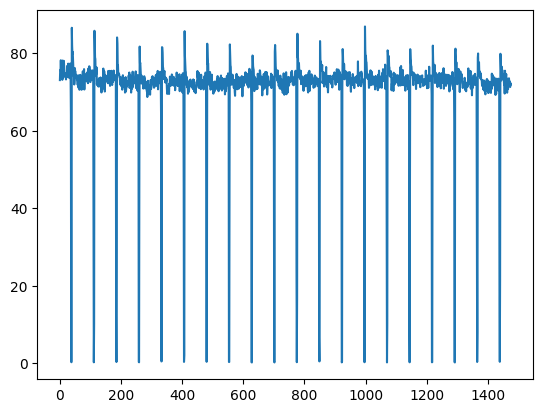

In [63]:
%matplotlib inline
fig,ax = plt.subplots()
ax.plot(pp.timeseries['outer_ring'][-1,:,:].mean(axis=0))

In [64]:
from pprint import pprint
pprint(pp.metadata['mark_points'])


{'custom_laser_power': None,
 'duration': 300.0,
 'indices': '9',
 'initial_delay': 5000.0,
 'inter_point_delay': 9700.0,
 'iteration_delay': 1000.0,
 'iterations': 1,
 'points_list': [{'Index': 9.0,
                  'IsSpiral': True,
                  'SpiralHeight': 0.103015372815038,
                  'SpiralSizeInMicrons': 9.99999999999999,
                  'SpiralWidth': 0.0788711448115137,
                  'X': 0.53265264805568,
                  'Y': 0.439782707654579}],
 'repetitions': 20,
 'spiral_revolutions': 1.0,
 'trigger': 'PFI1',
 'trigger_count': 1,
 'trigger_freq': 'None',
 'uncaging_laser': '617',
 'uncaging_power': 50}


In [84]:
frame_times = np.array(pp.metadata['frame_times']).mean(axis=1)
laser_on_mask = 0*frame_times

stim_times = [pp.metadata['mark_points']['initial_delay']/1000,]
for i in range(1, pp.metadata['mark_points']['repetitions']):
    stim_times.append(stim_times[-1] + pp.metadata['mark_points']['duration']/1000 + pp.metadata['mark_points']['inter_point_delay']/1000)


In [85]:
frame_times


array([6.77820850e-02, 2.03346255e-01, 3.38910425e-01, ...,
       1.99753804e+02, 1.99889369e+02, 2.00024933e+02], shape=(1476,))

In [86]:
stim_times

[5.0,
 15.0,
 25.0,
 35.0,
 45.0,
 55.0,
 65.0,
 75.0,
 85.0,
 95.0,
 105.0,
 115.0,
 125.0,
 135.0,
 145.0,
 155.0,
 165.0,
 175.0,
 185.0,
 195.0]

In [ ]:
responses = []
smallest_list = 1E6
for stim_time in stim_times:
    idx = np.argmin(np.abs(frame_times - stim_time+2))
    id_start = np.argmin(np.abs(frame_times - (stim_time+2 - 5)))
    id_end = np.argmin(np.abs(frame_times - (stim_time+2 + 8)))
    
    responses.append(pp.timeseries['outer_ring'][-1,:,id_start:id_end][np.newaxis,:])
    smallest_list = min(smallest_list, responses[-1].shape[1]) 
responses = np.vstack([resp[:,:smallest_list] for resp in responses])

In [92]:
responses.shape

(20, 59)

In [93]:
dt = np.mean(frame_times[1:] - frame_times[:-1])

/tmp/ipykernel_1935668/1822328005.py:10: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(responses, axis=0)
/tmp/ipykernel_1935668/1822328005.py:11: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  sem = sp.stats.sem(responses, axis=0, nan_policy='omit')


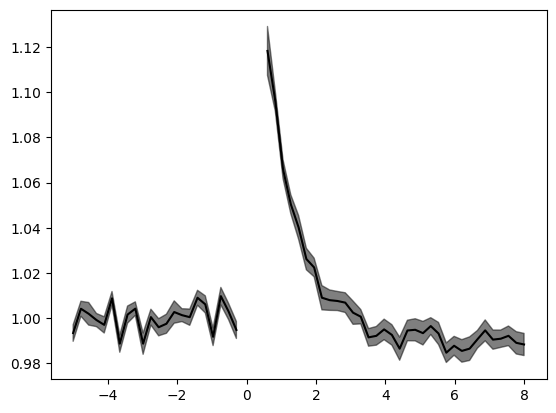

In [94]:
%matplotlib inline
fig,ax = plt.subplots()
time = np.linspace(-5, 8, num = responses.shape[1])
mask = (time >= -.1) & (time <= .4)
baseline_mask = time < -.1
responses[:,mask] = np.nan
baseline = np.nanmean(responses[:,baseline_mask],axis=1, keepdims=True)
responses /= baseline

mu = np.nanmean(responses, axis=0)
sem = sp.stats.sem(responses, axis=0, nan_policy='omit')
ax.plot(time, mu, color='k')
ax.fill_between(time, mu-sem, mu+sem, color='k', alpha=.5)
